In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.optimize
from scipy.optimize import minimize
from scipy.stats import norm
from scipy.special import logsumexp
import warnings
from scipy.optimize import curve_fit
from scipy.optimize import approx_fprime
import scipy.stats as stats
from pybads import BADS

from matplotlib.colors import LinearSegmentedColormap

# TEMP
warnings.simplefilter("ignore", category=FutureWarning)

from src.src import *

# Set some defaults
plt.rc("axes.spines", top=False, right=False)
plt.rcParams["mathtext.default"] = "regular"
sns.set_theme(font_scale=1.2)
sns.set_style("ticks")
# sns.set_palette('deep')

%config InlineBackend.figure_format = "retina"

## The Plan

### Parameter and model recovery 
1) Simulate data using best-fit parameters from each model (or samples from within the range of best-fits). For example, 100 simulations of each model within range of best-fit parameters.
2) Refit simulated data using MLE.
3) Correlate parameters used for simulation with recovered parameters.
4) Model comparison with AIC/BIC. 

In [2]:
# Read in behavioral data
sdt = pd.read_csv("../behavioural/data/processed-sdt.csv")
adapt = pd.read_csv("../behavioural/data/processed-adapt.csv")

# Read in csv with MLEs from all models
# Need a function to convert string back to numpy array
def converter(input_str):
    return np.fromstring(input_str[1:-1], sep=' ')

fits_sdt = pd.read_csv("model-fits/fits_sdt.csv", converters={"params":converter})
fits_adapt = pd.read_csv("model-fits/fits_adapt.csv", converters={"params":converter})
fits_sdt.head()


,SN,model,fit_task,nll,aic,bic,params,C,sigma_v,b,sigma_comb,alpha,beta,sigma_p,sigma_pert,aic_weighted,bic_weighted
0,1,vco,sdt,318.538186,643.076371,657.122697,"[3.41250859, 1.82921363, -0.11052107]",3.412509,1.829214,-0.110521,NaN,NaN,NaN,NaN,NaN,935.269293,950.448146
1,2,vco,sdt,286.700472,579.400945,593.447271,"[5.1097239, 2.46265332, 2.78463823]",5.109724,2.462653,2.784638,NaN,NaN,NaN,NaN,NaN,843.107896,858.289325
2,3,vco,sdt,466.611546,939.223091,953.189412,"[3.46698499, 3.8885529, 0.20789672]",3.466985,3.888553,0.207897,NaN,NaN,NaN,NaN,NaN,1309.749891,1324.719279
3,4,vco,sdt,367.046285,740.092570,754.142653,"[4.10714784, 2.64430312, 0.25845051]",4.107148,2.644303,0.258451,NaN,NaN,NaN,NaN,NaN,1071.766434,1086.934960
4,5,vco,sdt,266.566256,539.132513,553.178838,"[4.82265147, 2.26528203, 0.07786751]",4.822651,2.265282,0.077868,NaN,NaN,NaN,NaN,NaN,783.651936,798.830789


## Processing for SDT simulations

In [3]:
# Group by model and stack params into 2d array
params = fits_sdt.groupby("model")["params"].apply(np.stack)
params_vco = params["vco"]
params_co = params["co"]
params_piece = params["piece"]

# Set upper and lower bounds on simulated params
vco_lb = params_vco.min(axis=0)
vco_ub = params_vco.max(axis=0)
co_lb = params_co.min(axis=0)
co_ub = params_co.max(axis=0)
piece_lb = params_piece.min(axis=0)
piece_ub = params_piece.max(axis=0)

# Choose subject to extract experiment parameters from (same for all 16 subjects)
subj_id = 1
sdt = sdt.loc[sdt["TN"] > 106, :].reset_index(drop=True)
sdt_subj = sdt.loc[(sdt["SN"] == subj_id) & (sdt["session"] == "sdt"), :].reset_index(drop=True)
cols_to_copy = ["SN", "x_f", "session", "delta_xv", "vis_fb", "sigma_motor_sdt"]
simsubj = pd.DataFrame()
simsubj[cols_to_copy] = sdt_subj[cols_to_copy]
simsubj["no_fit"] = False


In [4]:
%%time
# How many model simulations?
n_modelsims = 10

# Determine how many MC simulations to run
n_mcsims = 100
n_inits = 1

# We switch off the printing from BADS
options = {"display" : 'off'}

fit_task = "sdt"

n_decimals = 5

models = ["vco", "co", "piece"]
# models = ["vco", "co"]
simulated_params = []
recovered_params = []
model = []
winner_bic = []
winner_aic = []
iteration = []

# Initialize
resp_vco = np.zeros((n_modelsims, len(sdt_subj)))
resp_co = np.zeros((n_modelsims, len(sdt_subj)))
resp_piece = np.zeros((n_modelsims, len(sdt_subj)))

# This next loop is for both model and parameter recovery
for i in range(n_modelsims):
    print(f"i:{i}")
    # Generate parameter vals for each model
    vco_simparams = np.random.uniform(low=vco_lb, high=vco_ub)
    co_simparams = np.random.uniform(low=co_lb, high=co_ub)
    piece_simparams = np.random.uniform(low=piece_lb, high=piece_ub)

    # Loop through models to simulate responses
    for j in range(len(models)):
        print("    j:{j}")
        if j == 0:
            # VCO model
            resp_vco[i, :] = vco_simulate_sdt(
                df=simsubj,
                C=vco_simparams[0], 
                sigma_v=vco_simparams[1], 
                b=vco_simparams[2], 
            )
            simulated_model = "vco"
            simulated_params.append(vco_simparams)
            simsubj["pert_resp"] = resp_vco[i, :]  
        elif j == 1: 
            # CO model
            resp_co[i, :] = co_simulate_sdt(
                df=simsubj,
                C=co_simparams[0], 
                sigma_comb=co_simparams[1],
                b=None
            )
            simulated_model = "co"
            simulated_params.append(co_simparams)
            simsubj["pert_resp"] = resp_co[i, :]
        elif j == 2:
            # PIECE model
            resp_piece[i, :] = piece_simulate_sdt(
                df=simsubj,
                alpha=piece_simparams[0], 
                beta=piece_simparams[1],
                sigma_p=piece_simparams[2],
                sigma_pert=piece_simparams[3],
                b=piece_simparams[4],
            )
            simulated_model = "piece"
            simulated_params.append(piece_simparams)
            simsubj["pert_resp"] = resp_piece[i, :]
            
        # Fit simulated data:
        # VCO parameter bounds (C, sigma_v, b) 
        bounds       = [(0.1, 10), (0.1, 10.0), (-5, 5)]
        plaus_bounds = [(0.5, 5), (0.5, 6), (-2.5, 2.5)]
        fits_vco, aic_vco, bic_vco = fit_bads("vco", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                              n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "vco":
            recovered_params.append(np.round(fits_vco.x, n_decimals))

        # CO parameter bounds (C, sigma_comb) 
        bounds = [(0.1, 10), (0.1, 10.0)]
        plaus_bounds = [(0.5, 5), (0.5, 6)]
        fits_co, aic_co, bic_co = fit_bads("co", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                     n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "co":
            recovered_params.append(np.round(fits_co.x, n_decimals))

        # PIECE parameter bounds: alpha, beta, sigma_p, sigma_pert, b,
        bounds       = ((0.1, 5), (0.001, 1), (0.1, 10), (0.1, 120), (-5, 5))
        plaus_bounds = ((0.5, 4), (0.01, 0.5), (0.3, 6), (3, 20), (-2.5, 2.5))
        fits_piece, aic_piece, bic_piece = fit_bads("piece", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                        n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "piece":
            recovered_params.append(np.round(fits_piece.x, n_decimals))

        # These lines are for model comparison/recovery: store winning model
        winner_aic.append(models[np.argmin([aic_vco, aic_co, aic_piece])])
        winner_bic.append(models[np.argmin([bic_vco, bic_co, bic_piece])])
        # winner_aic.append(models[np.argmin([aic_vco, aic_co, ])])
        # winner_bic.append(models[np.argmin([bic_vco, bic_co, ])])
        
        # Update variables to properly index in dataframe
        model.append(simulated_model)
        iteration.append(i)

# Store variables in data frame
sdt_recovery = pd.DataFrame({
    "iteration": iteration,
    "model":model, 
    "winner_aic":winner_aic, 
    "winner_bic":winner_bic,
    "simulated_params": simulated_params,
    "recovered_params": recovered_params
})
        

0
0
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...


/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


1
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
2
Subject Number: 1
Running optimization 0...


/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
1
0
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
1
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
2
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
2
0
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
1
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
2
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
3
0
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...


/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


... (27 outputs left out)

/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


2
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...


/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


CPU times: user 1h 1min 54s, sys: 1h 18min 41s, total: 2h 20min 36s
Wall time: 15min 37s


---
## Processing for adaptation simulations

In [53]:
# Group by model and stack params into 2d array
params = fits_adapt.groupby("model")["params"].apply(np.stack)
params_vco = params["vco"]
params_co = params["co"]
params_piece = params["piece"]

# Set upper and lower bounds on simulated params
vco_lb = params_vco.min(axis=0)
vco_ub = params_vco.max(axis=0)
co_lb = params_co.min(axis=0)
co_ub = params_co.max(axis=0)
piece_lb = params_piece.min(axis=0)
piece_ub = params_piece.max(axis=0)


# Choose subject to extract experiment parameters from (same for all 16 subjects)
subj_id = 1
adapt = adapt.loc[adapt["TN"] > 100, :].reset_index(drop=True)
adapt_subj = adapt.loc[(adapt["SN"] == subj_id) & (adapt["session"] == "adapt"), :].reset_index(drop=True)
cols_to_copy = ["SN", "TN", "session", "delta_xv", "vis_fb", "x_f", "sigma_motor_adapt"]
simsubj = pd.DataFrame()
simsubj[cols_to_copy] = adapt_subj[cols_to_copy]
simsubj["no_fit"] = False

In [54]:
%%time
# How many model simulations?
n_modelsims = 5

# Determine how many MC simulations to run
n_mcsims = 1000
n_inits = 1

# We switch off the printing from BADS
options = {"display" : 'off'}

fit_task = "adapt"

n_decimals = 5

models = ["vco", "co", "piece"]
# models = ["vco", "co"]
simulated_params = []
recovered_params = []
model = []
winner_bic = []
winner_aic = []
iteration = []

resp_vco = np.zeros((n_modelsims, len(adapt_subj)))
resp_co = np.zeros((n_modelsims, len(adapt_subj)))
resp_piece = np.zeros((n_modelsims, len(adapt_subj)))

# This next loop is for both model and parameter recovery
for i in range(n_modelsims):
    print(f"i:{i}")
    # Generate parameter vals for each model
    vco_simparams = np.random.uniform(low=vco_lb, high=vco_ub)
    co_simparams = np.random.uniform(low=co_lb, high=co_ub)
    piece_simparams = np.random.uniform(low=piece_lb, high=piece_ub)

    # Loop through models
    for j in range(len(models)):
        print(f"j:{    j}")
        if j == 0:
            # VCO model
            resp_vco[i, :] = vco_simulate_adapt(
                df=simsubj,
                C=vco_simparams[0], 
                B=vco_simparams[1], 
                sigma_v=vco_simparams[2], 
                b=vco_simparams[3], 
            )
            simulated_model = "vco"
            simulated_params.append(vco_simparams)
            simsubj["x_f"] = resp_vco[i, :]  
        elif j == 1: 
            # CO model
            resp_co[i, :] = co_simulate_adapt(
                df=simsubj,
                C=co_simparams[0],
                B=co_simparams[1],
                sigma_comb=co_simparams[2],
                b=co_simparams[3],
            )
            simulated_model = "co"
            simulated_params.append(co_simparams)
            simsubj["x_f"] = resp_co[i, :]
        elif j == 2:
            # PIECE model
            resp_piece[i, :] = piece_simulate_adapt(
                df=simsubj,
                alpha=piece_simparams[0], 
                beta=piece_simparams[1],
                sigma_p=piece_simparams[2],
                sigma_pert=piece_simparams[3],
                b=piece_simparams[4],
            )
            simulated_model = "piece"
            simulated_params.append(piece_simparams)
            simsubj["x_f"] = resp_piece[i, :]
            
        # Fit simulated data:
        # VCO: Parameter bounds (C, B, sigma_v, b) 
        bounds       = [(0.1, 10), (0.01, 1), (0.1, 10.0), (-5, 5)]
        plaus_bounds = [(0.5, 5), (0.05, 0.6), (0.5, 6), (-2.5, 2.5)]
        fits_vco, aic_vco, bic_vco = fit_bads("vco", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                              n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "vco":
            recovered_params.append(np.round(fits_vco.x, n_decimals))

        # CO parameter bounds (C, B, sigma_comb, b) 
        bounds       = [(0.1, 10), (0.01, 1), (0.1, 10.0), (-5, 5)]
        plaus_bounds = [(0.5, 5), (0.05, 0.6), (0.5, 6), (-2.5, 2.5)]
        fits_co, aic_co, bic_co = fit_bads("co", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                     n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "co":
            recovered_params.append(np.round(fits_co.x, n_decimals))

        # PIECE parameter bounds: alpha, beta, sigma_p, sigma_pert, b,
        bounds       = ((0.1, 5), (0.001, 1), (0.1, 10), (0.1, 120), (-5, 5))
        plaus_bounds = ((0.5, 4), (0.01, 0.5), (0.3, 6), (3, 20), (-2.5, 2.5))
        fits_piece, aic_piece, bic_piece = fit_bads("piece", subj_id, simsubj, bounds, plaus_bounds, n_inits=n_inits, 
                                        n_sims=n_mcsims, fit_task=fit_task, options=options)
        # This conditional is for parameter recovery
        if simulated_model == "piece":
            recovered_params.append(np.round(fits_piece.x, n_decimals))

        # These lines are for model comparison/recovery: store winning model
        winner_aic.append(models[np.argmin([aic_vco, aic_co, aic_piece])])
        winner_bic.append(models[np.argmin([bic_vco, bic_co, bic_piece])])
        # winner_aic.append(models[np.argmin([aic_vco, aic_co, ])])
        # winner_bic.append(models[np.argmin([bic_vco, bic_co, ])])
        
        # Update variables to properly index in dataframe
        model.append(simulated_model)
        iteration.append(i)

# Store variables in data frame
adapt_recovery = pd.DataFrame({
    "iteration": iteration,
    "model":model, 
    "winner_aic":winner_aic, 
    "winner_bic":winner_bic,
    "simulated_params": simulated_params,
    "recovered_params": recovered_params, 
})
        

0
0
Subject Number: 1
Running optimization 0...


/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


Subject Number: 1
Running optimization 0...


/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


Subject Number: 1
Running optimization 0...
1
Subject Number: 1
Running optimization 0...


/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


... (25 outputs left out)

/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


Subject Number: 1
Running optimization 0...
2
Subject Number: 1
Running optimization 0...


/opt/anaconda3/envs/ige-ege/lib/python3.11/site-packages/pybads/init_functions/init_sobol.py:39: RuntimeWarning: invalid value encountered in cast
  str_seed = u0[0 : np.minimum(11, len(u0))].astype(np.uint64)


Subject Number: 1
Running optimization 0...
Subject Number: 1
Running optimization 0...
CPU times: user 3h 30min 33s, sys: 5h 41min 43s, total: 9h 12min 17s
Wall time: 1h 14min 47s


---
## Read / Write parameters

In [51]:
# Save MLEs? Set to True ONLY if you want to save a new set of fit parameters.
write_data = False

# Read-in saved parameters? Set to True if you want to check previous fit(s).
read_data = False
read_sdt = False
read_adapt = False

# Helper function
def converter(input_str):
    return np.fromstring(input_str[1:-1], sep=' ')
    
# Write data to csv
if write_data:
    if sdt_recovery:
        sdt_recovery.to_csv("model-fits/sdt_model_recovery.csv", index=False)
    if adapt_recovery:
        adapt_recovery.to_csv("model-fits/adapt_model_recovery.csv", index=False)

# Read in csv from previous param/model recovery analysis; need "converter" helper fxn
# because parameters must be converted from string representation of values to 1-d NumPy 
# array
if read_data:
    if read_sdt:
        sdt_recovery = pd.read_csv("model-fits/sdt_model_recovery.csv", 
                               converters={"simulated_params":converter, 
                                        "recovered_params":converter})
    if read_adapt: 
        adapt_recovery = pd.read_csv("model-fits/adapt_model_recovery.csv", 
                               converters={"simulated_params":converter, 
                                          "recovered_params":converter})


---
## Model recovery analysis for signal-detection task

Build confusion matrix. 

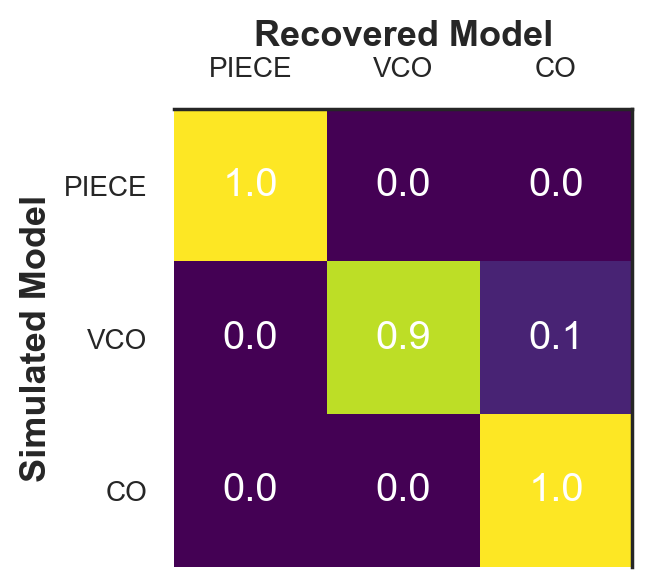

In [7]:
save = 0
df_recovery = sdt_recovery
models = ["piece", "vco", "co"]
y_true = sdt_recovery["model"]
y_pred = sdt_recovery["winner_aic"]
df_confusion = pd.crosstab(sdt_recovery["model"], sdt_recovery["winner_aic"], normalize="index")
df_confusion

def plot_confusion_matrix(df_confusion, title=None, save=0):
    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    ax.matshow(df_confusion, cmap="viridis") 
    plt.title(title, fontsize=13)
    tick_marks = np.arange(len(df_confusion.columns))
    ax.set_xticks(tick_marks, ["PIECE", "VCO", "CO"])
    ax.xaxis.tick_top()
    ax.set_yticks(tick_marks, ["PIECE", "VCO", "CO"])
    ax.set_ylabel("Simulated Model", weight="bold", fontsize=13)
    ax.set_xlabel("Recovered Model", weight="bold", fontsize=13)
    ax.xaxis.set_label_position('top')
    ax.tick_params(left=False, top=False)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    # plt.text(-2, -1.2, "b", weight="bold", fontsize=14)

    # Loop over data dimensions and create text annotations.
    for i in range(len(models)):
        for j in range(len(models)):
            ax.text(j, i, df_confusion.iloc[i, j],
                           ha="center", va="center", color="w")
    plt.tight_layout()
    # if save == 1:
    #     plt.savefig("images/confusion_matrix.svg")

plot_confusion_matrix(df_confusion, save=1)

---
## Parameter recovery analysis for signal-detection task

In [43]:
# Unpack parameters and stack them into 2d arrays
df_simparams = sdt_recovery.groupby("model")["simulated_params"].apply(np.stack)
df_fitparams = sdt_recovery.groupby("model")["recovered_params"].apply(np.stack)

# Select PIECE parameter matrices
piece_simparams = df_simparams["piece"]
piece_fitparams = df_fitparams["piece"]

# Select VCO parameter matrices
vco_simparams = df_simparams["vco"]
vco_fitparams = df_fitparams["vco"]

# Select CO parameter matrices
co_simparams = df_simparams["co"]
co_fitparams = df_fitparams["co"]


In [9]:
# Compute correlation coefficients between true and recovered params
# PIECE
r_piece_alpha, p_piece_alpha = stats.pearsonr(
    x=piece_simparams[:, 0], y=piece_fitparams[0, :])
r_piece_beta, p_piece_beta = stats.pearsonr(
    x=piece_simparams[:, 1], y=piece_fitparams[:, 1])
r_piece_sigma_p, p_piece_sigma_p = stats.pearsonr(
    x=piece_simparams[:, 2], y=piece_fitparams[:, 2])
r_piece_sigma_pert, p_piece_sigma_pert = stats.pearsonr(
    x=piece_simparams[:, 3], y=piece_fitparams[:, 3])
r_piece_b, p_piece_b = stats.pearsonr(
    x=piece_simparams[:, 4], y=piece_fitparams[:, 4])
print(np.array([r_piece_alpha, r_piece_beta, r_piece_sigma_p, r_piece_sigma_pert, r_piece_b]).round(4))
print(np.array([p_piece_alpha, p_piece_beta, p_piece_sigma_p, p_piece_sigma_pert, p_piece_b]).round(4))


# VCO
r_vco_C, p_vco_C = stats.pearsonr(x=vco_simparams[:, 0], y=vco_fitparams[:, 0])
# r_vco_B, p_vco_B = stats.pearsonr(x=vco_simparams[:, 1], y=vco_fitparams[:, 1])
r_vco_sigma_v, p_vco_sigma_v = stats.pearsonr(x=vco_simparams[:, 2], y=vco_fitparams[:, 2])
r_vco_b, p_vco_b = stats.pearsonr(x=vco_simparams[:, 3], y=vco_fitparams[:, 3])
print(np.array([r_vco_C, r_vco_sigma_v, r_vco_b]).round(4))
print(np.array([p_vco_C, p_vco_sigma_v, p_vco_b]).round(4))


# CO
r_co_C, p_co_C = stats.pearsonr(x=co_simparams[:, 0], y=co_fitparams[:, 0])
# r_co_B, p_co_B = stats.pearsonr(x=co_simparams[:, 1], y=co_fitparams[:, 1])
r_co_sigma_comb, p_co_sigma_comb = stats.pearsonr(x=co_simparams[:, 2], y=co_fitparams[:, 2])
# r_co_b, p_co_b = stats.pearsonr(x=co_simparams[:, 3], y=co_fitparams[:, 3])
print(np.array([r_co_C, r_co_sigma_comb, ]).round(4))
print(np.array([p_co_C, p_co_sigma_comb, ]).round(4))

array([[ 1.7886454 ,  0.05023786,  4.60941352,  8.87657597,  1.20245534],
       [ 1.27610314,  0.19717236,  2.83478584,  2.93861167, -1.54671735],
       [ 1.59376212,  0.058322  ,  3.32401471, 11.3948933 ,  1.6766641 ],
       [ 0.35676719,  0.15804079,  1.65208197,  7.03471357, -0.62064662],
       [ 0.30243785,  0.06572003,  2.99438067,  6.60026763, -0.37312744],
       [ 0.87291532,  0.20672412,  2.0852619 , 11.73758355, -0.16698625],
       [ 0.86055033,  0.1794622 ,  2.81588461,  4.61631337,  1.92473501],
       [ 2.44771419,  0.03086348,  2.91891613, 11.27217047,  0.84314084],
       [ 1.38744189,  0.07105882,  4.84889514,  3.23465866,  1.85520954],
       [ 2.01812016,  0.2497804 ,  2.63150152,  0.56006871, -0.41633793]])

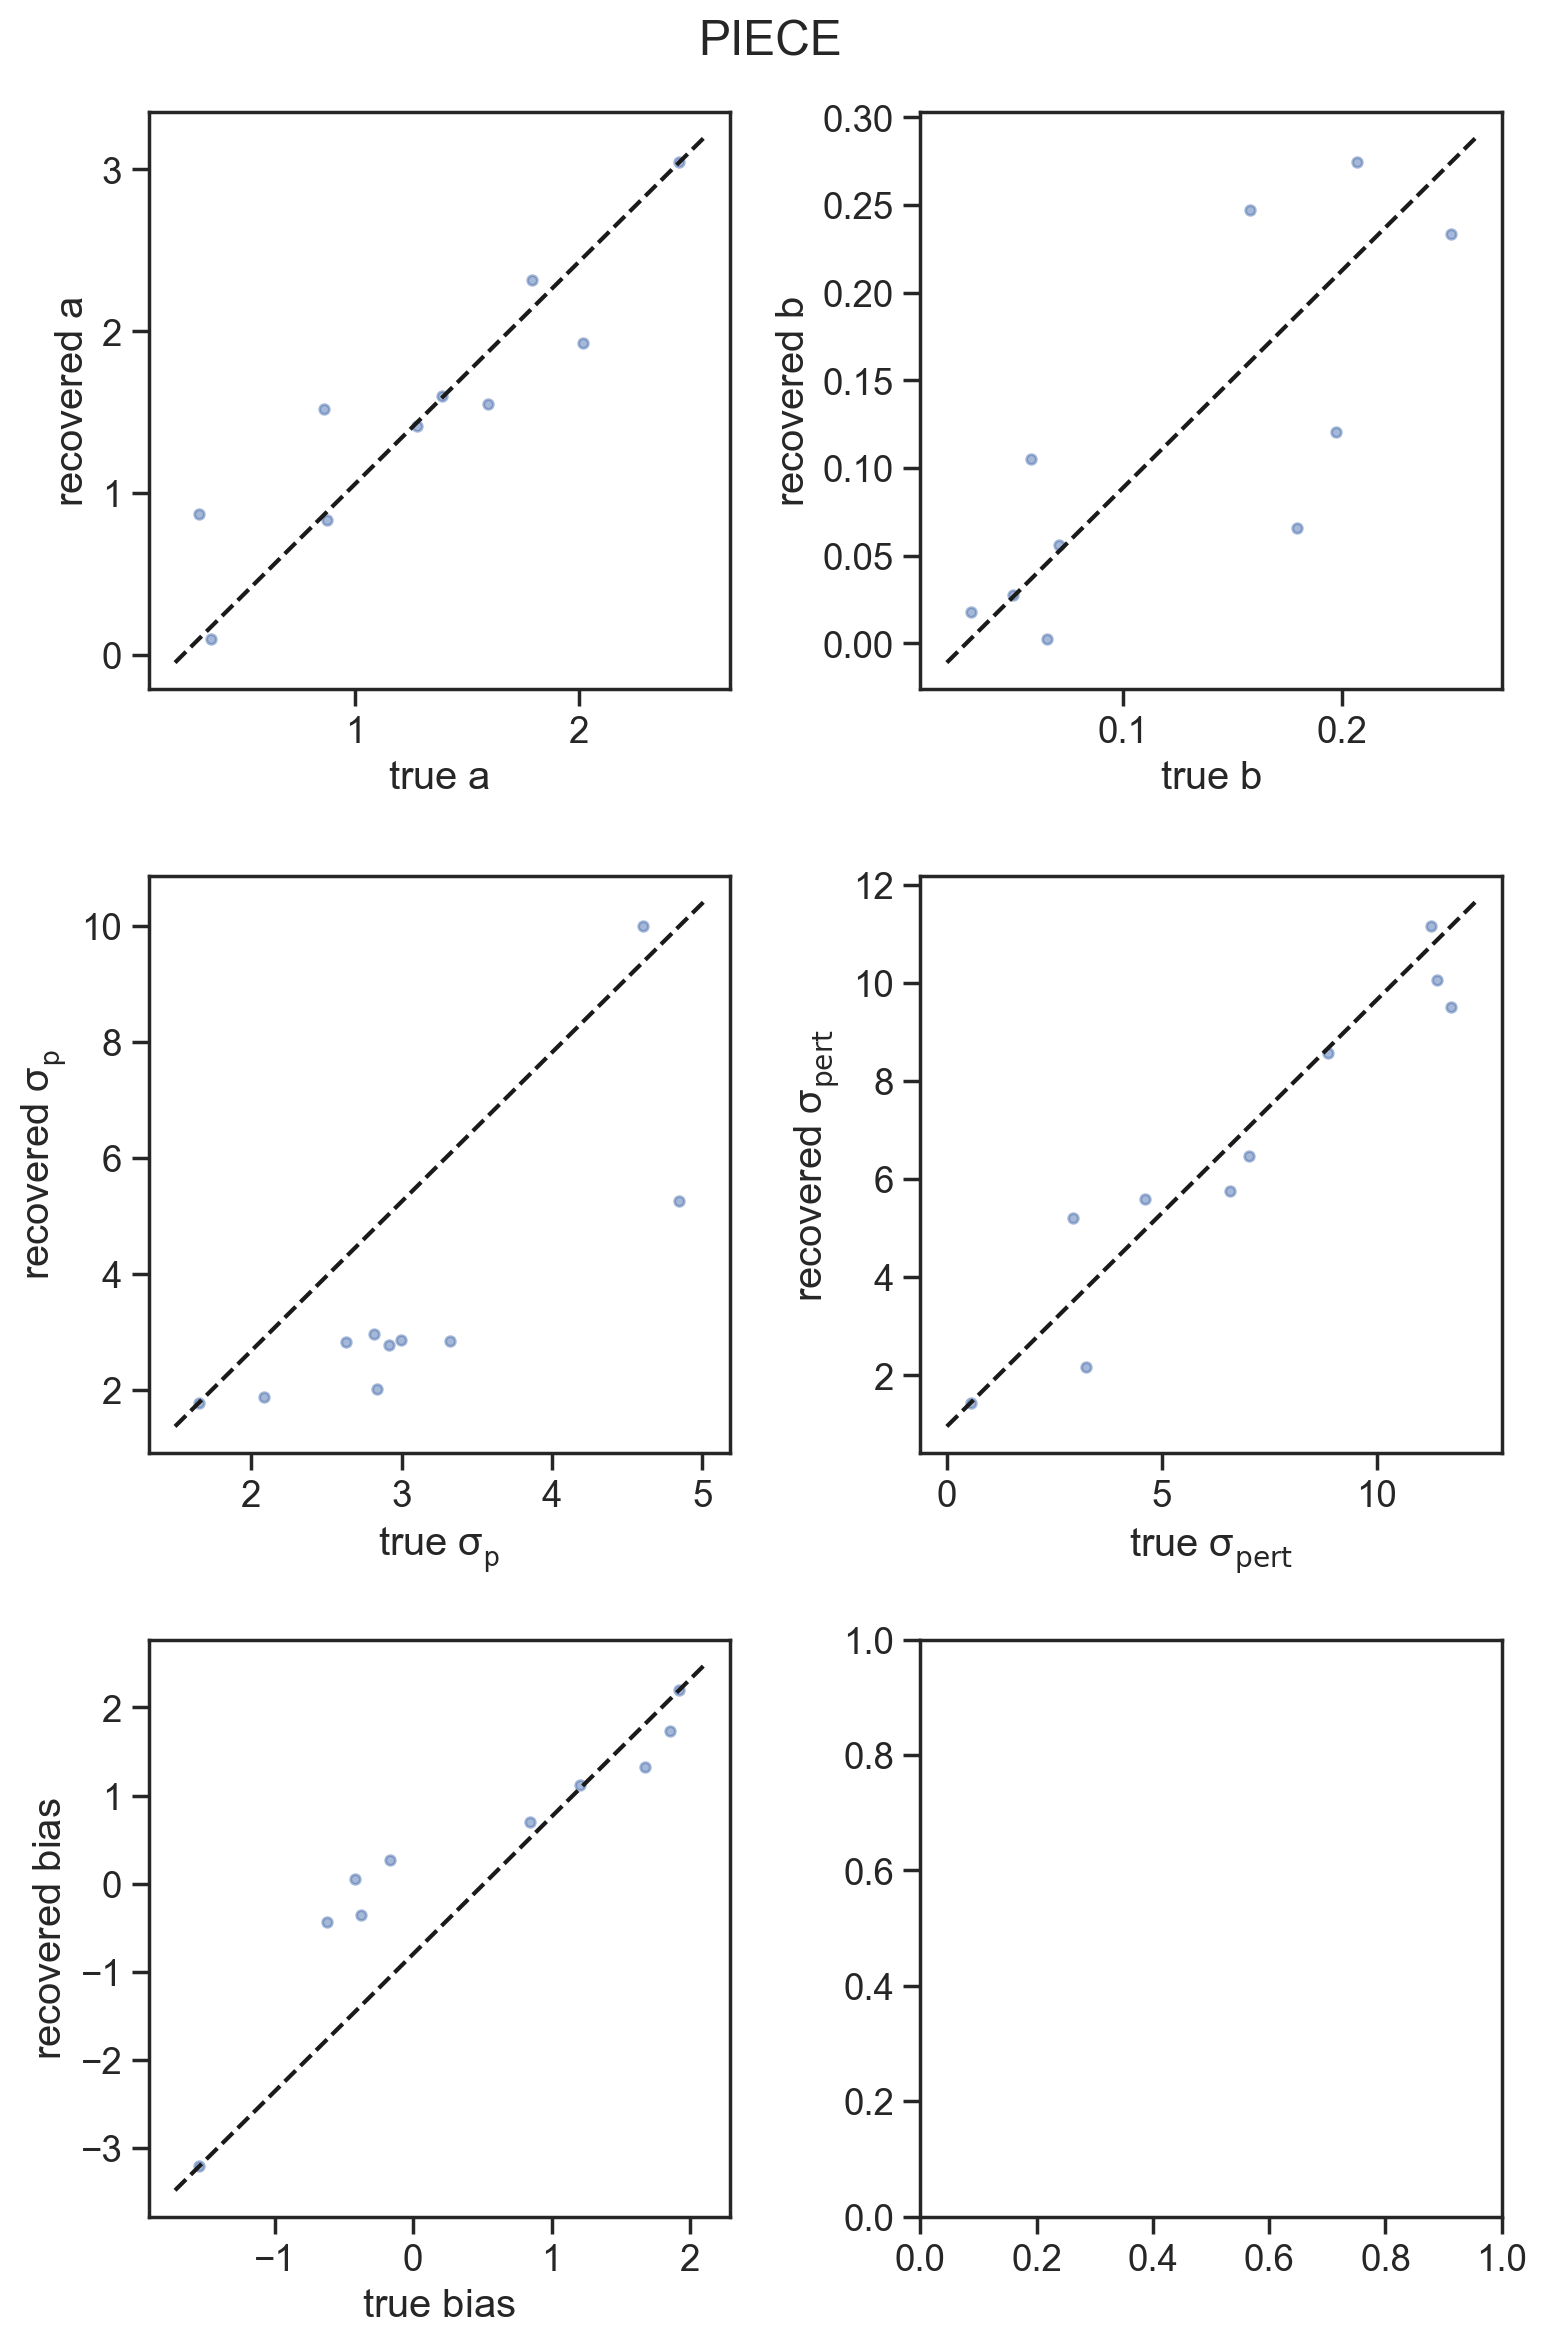

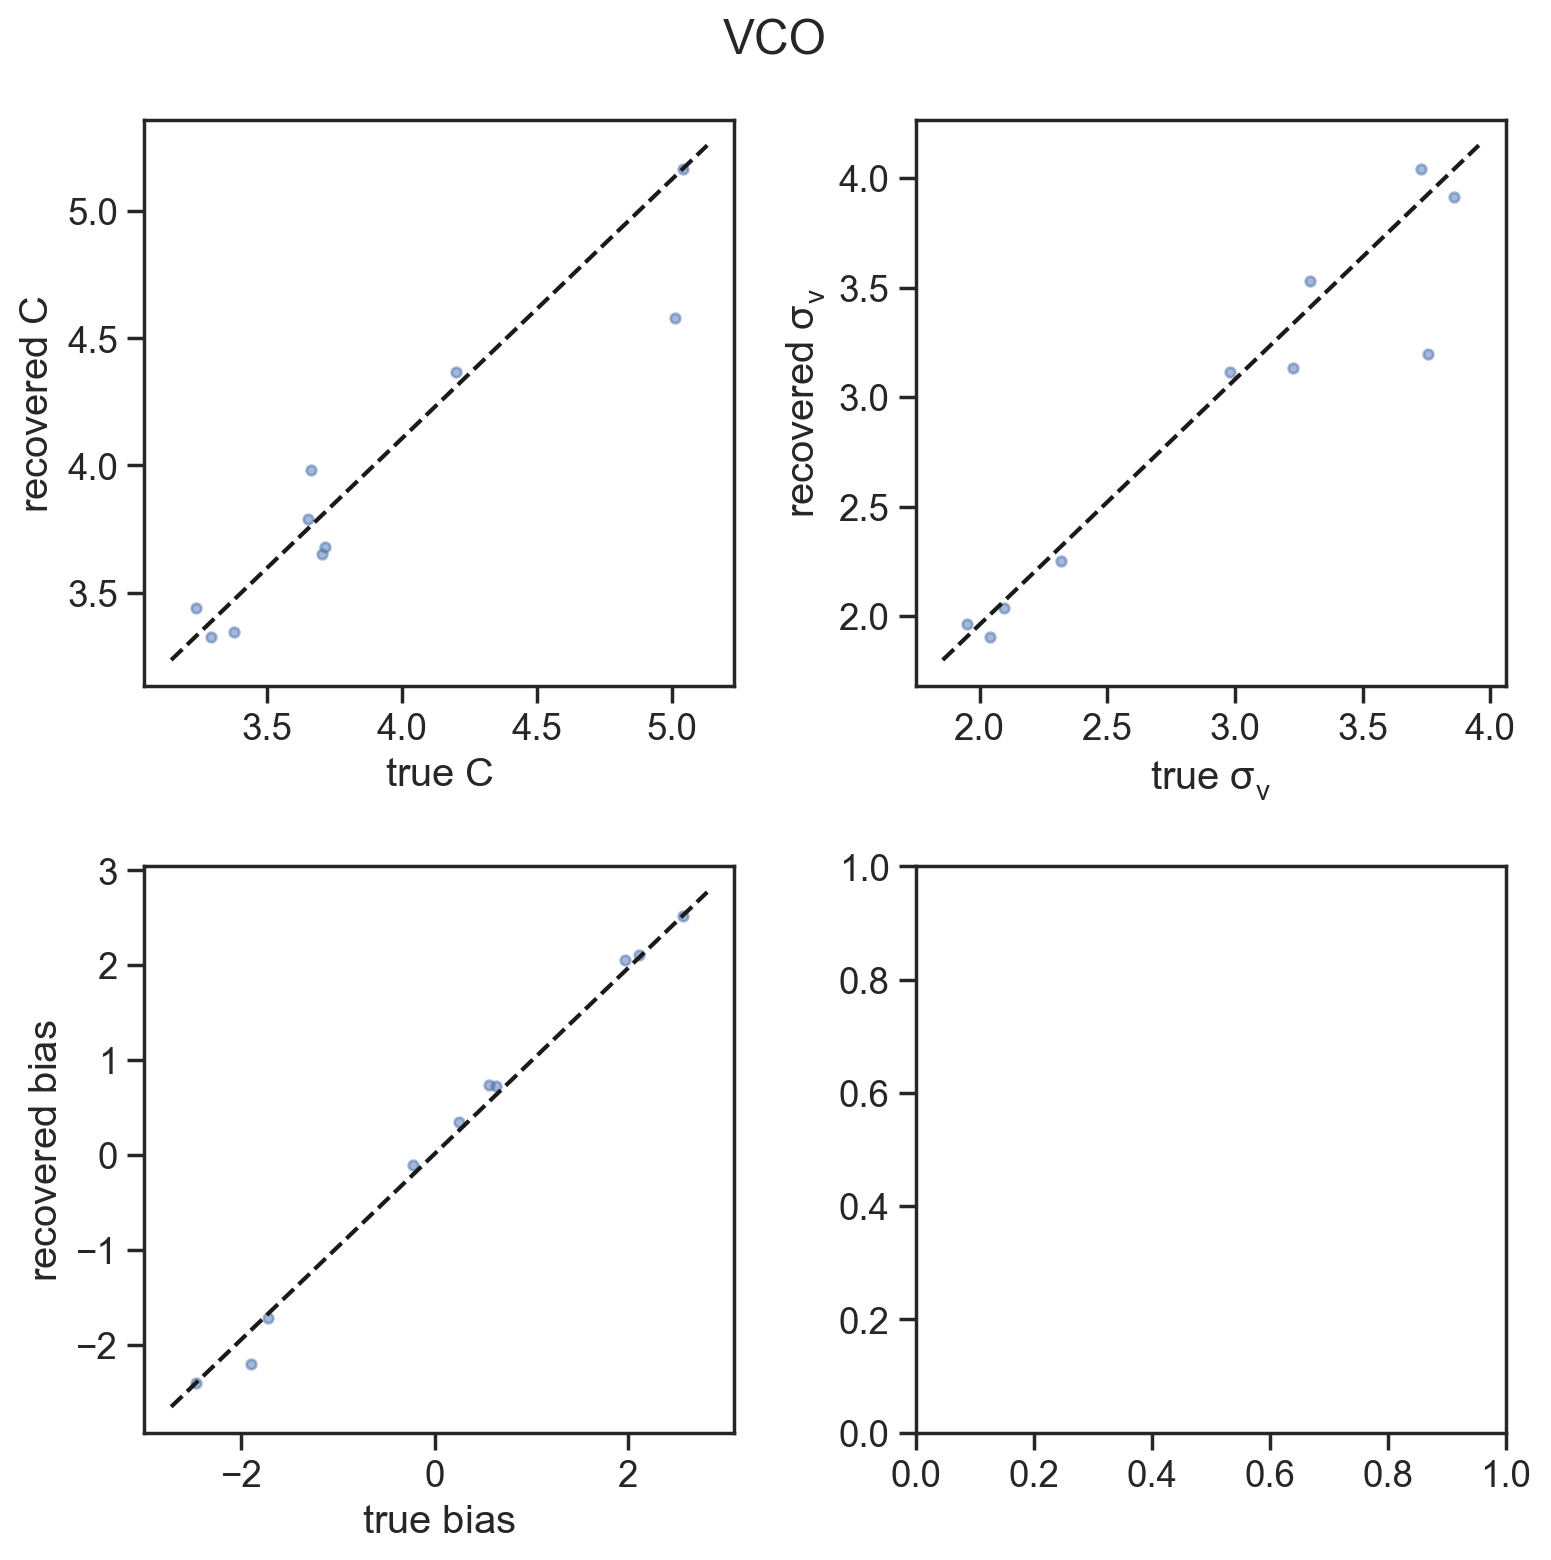

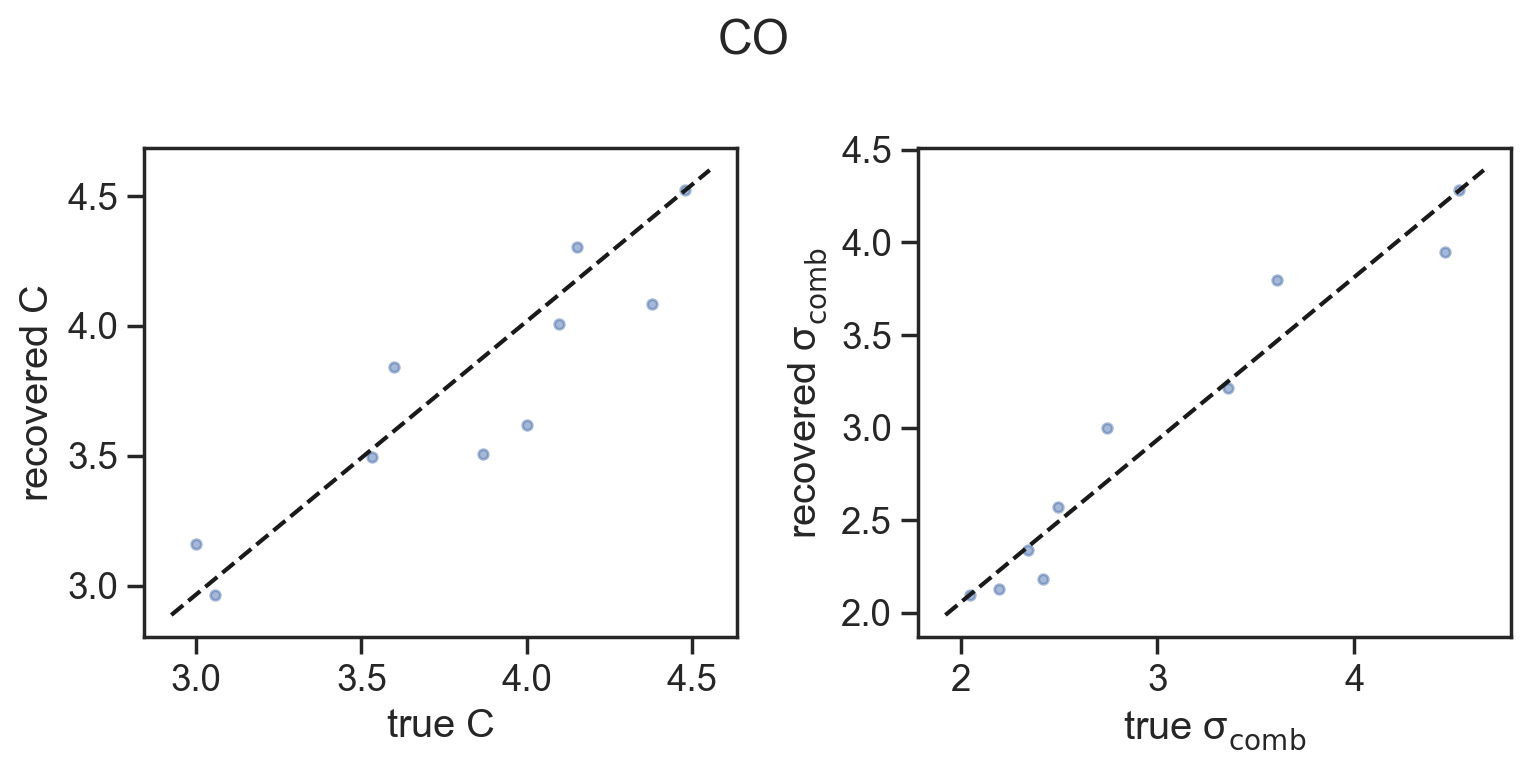

In [49]:
# Plot param recovery for PIECE
fig, axs = plt.subplots(3, 2, figsize=(8, 12))
xaxes = [r"true $a$", r"true $b$", r"true $\sigma_p$", r"true $\sigma_\text{pert}$", 
         r"true $bias$"] 
yaxes = [r"recovered $a$", r"recovered $b$", r"recovered $\sigma_p$", 
         r"recovered $\sigma_\text{pert}$", r"recovered $bias$"] 
for i, ax in enumerate(axs.flatten()[:-1]):
    ax.scatter(piece_simparams[:, i], piece_fitparams[:, i], alpha=0.5, s=12)
    ax.plot(ax.get_xlim(), ax.get_ylim(), color="k", linestyle="--")
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])
    plt.tight_layout()
    fig.suptitle("PIECE")
axs.flatten()[-1].set_axis_off()

# Plot param recovery for VCO
fig, axs = plt.subplots(2, 2, figsize=(8, 8))
xaxes = [r"true $C$", r"true $\sigma_v$", r"true $bias$"] 
yaxes = [r"recovered $C$", r"recovered $\sigma_v$", r"recovered $bias$"] 
for i, ax in enumerate(axs.flatten()[:-1]):
    ax.scatter(vco_simparams[:, i], vco_fitparams[:, i], alpha=0.5, s=12)
    ax.plot(ax.get_xlim(), ax.get_ylim(), color="k", linestyle="--")
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])
    plt.tight_layout()
    fig.suptitle("VCO")
axs.flatten()[-1].set_axis_off()

# Plot param recovery for CO
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
xaxes = [r"true $C$", r"true $\sigma_\text{comb}$"] 
yaxes = [r"recovered $C$", r"recovered $\sigma_\text{comb}$"] 
for i, ax in enumerate(axs.flatten()):
    ax.scatter(co_simparams[:, i], co_fitparams[:, i], alpha=0.5, s=12)
    ax.plot(ax.get_xlim(), ax.get_ylim(), color="k", linestyle="--")
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])
    plt.tight_layout()
    fig.suptitle("CO")

---
## Model recovery analysis for adaptation task

Build confusion matrix. 

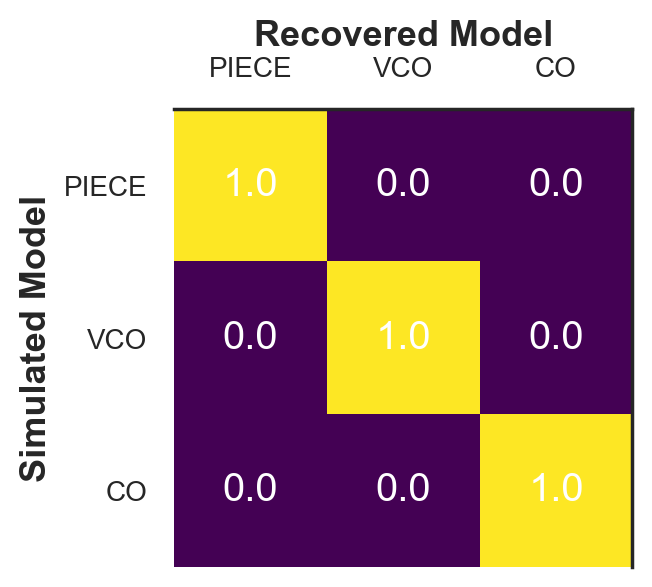

In [55]:
save = 0
df_recovery = adapt_recovery
models = ["piece", "vco", "co"]
y_true = adapt_recovery["model"]
y_pred = adapt_recovery["winner_aic"]
df_confusion = pd.crosstab(adapt_recovery["model"], adapt_recovery["winner_aic"], normalize="index")
df_confusion

def plot_confusion_matrix(df_confusion, title=None, save=0):
    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    ax.matshow(df_confusion, cmap="viridis") 
    plt.title(title, fontsize=13)
    tick_marks = np.arange(len(df_confusion.columns))
    ax.set_xticks(tick_marks, ["PIECE", "VCO", "CO"])
    ax.xaxis.tick_top()
    ax.set_yticks(tick_marks, ["PIECE", "VCO", "CO"])
    ax.set_ylabel("Simulated Model", weight="bold", fontsize=13)
    ax.set_xlabel("Recovered Model", weight="bold", fontsize=13)
    ax.xaxis.set_label_position('top')
    ax.tick_params(left=False, top=False)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    # plt.text(-2, -1.2, "b", weight="bold", fontsize=14)

    # Loop over data dimensions and create text annotations.
    for i in range(len(models)):
        for j in range(len(models)):
            ax.text(j, i, df_confusion.iloc[i, j],
                           ha="center", va="center", color="w")
    plt.tight_layout()
    # if save == 1:
    #     plt.savefig("images/confusion_matrix.svg")

plot_confusion_matrix(df_confusion, save=1)

---
## Parameter recovery analysis for adaptation task

In [56]:
# Unpack parameters and stack them into 2d arrays
df_simparams = adapt_recovery.groupby("model")["simulated_params"].apply(np.stack)
df_fitparams = adapt_recovery.groupby("model")["recovered_params"].apply(np.stack)

# Select PIECE parameter matrices
piece_simparams = df_simparams["piece"]
piece_fitparams = df_fitparams["piece"]

# Select VCO parameter matrices
vco_simparams = df_simparams["vco"]
vco_fitparams = df_fitparams["vco"]

# Select CO parameter matrices
co_simparams = df_simparams["co"]
co_fitparams = df_fitparams["co"]


In [67]:
# Compute correlation coefficients between true and recovered params
# PIECE
r_piece_alpha, p_piece_alpha = stats.pearsonr(
    x=piece_simparams[:, 0], y=piece_fitparams[0, :])
r_piece_beta, p_piece_beta = stats.pearsonr(
    x=piece_simparams[:, 1], y=piece_fitparams[:, 1])
r_piece_sigma_p, p_piece_sigma_p = stats.pearsonr(
    x=piece_simparams[:, 2], y=piece_fitparams[:, 2])
r_piece_sigma_pert, p_piece_sigma_pert = stats.pearsonr(
    x=piece_simparams[:, 3], y=piece_fitparams[:, 3])
r_piece_b, p_piece_b = stats.pearsonr(
    x=piece_simparams[:, 4], y=piece_fitparams[:, 4])
print(np.array([r_piece_alpha, r_piece_beta, r_piece_sigma_p, r_piece_sigma_pert, r_piece_b]).round(4))
print(np.array([p_piece_alpha, p_piece_beta, p_piece_sigma_p, p_piece_sigma_pert, p_piece_b]).round(4))


# VCO
r_vco_C, p_vco_C = stats.pearsonr(x=vco_simparams[:, 0], y=vco_fitparams[:, 0])
r_vco_B, p_vco_B = stats.pearsonr(x=vco_simparams[:, 1], y=vco_fitparams[:, 1])
r_vco_sigma_v, p_vco_sigma_v = stats.pearsonr(x=vco_simparams[:, 2], y=vco_fitparams[:, 2])
r_vco_b, p_vco_b = stats.pearsonr(x=vco_simparams[:, 3], y=vco_fitparams[:, 3])
print(np.array([r_vco_C, r_vco_B, r_vco_sigma_v, r_vco_b]).round(4))
print(np.array([p_vco_C, p_vco_B, p_vco_sigma_v, p_vco_b]).round(4))

# CO
r_co_C, p_co_C = stats.pearsonr(x=co_simparams[:, 0], y=co_fitparams[:, 0])
r_co_B, p_co_B = stats.pearsonr(x=co_simparams[:, 1], y=co_fitparams[:, 1])
r_co_sigma_comb, p_co_sigma_comb = stats.pearsonr(x=co_simparams[:, 2], y=co_fitparams[:, 2])
r_co_b, p_co_b = stats.pearsonr(x=co_simparams[:, 3], y=co_fitparams[:, 3])
print(np.array([r_co_C, r_co_B, r_co_sigma_comb, r_co_b]).round(4))
print(np.array([p_co_C, p_co_B, p_co_sigma_comb, p_co_b]).round(4))

[-0.8486  0.5209 -0.3288  0.7439  0.9972]
[6.910e-02 3.682e-01 5.890e-01 1.494e-01 2.000e-04]
[0.42   0.7833 0.9716 0.9887]
[0.4814 0.1171 0.0057 0.0014]
[-0.0647  0.8165  0.8754  0.9943]
[9.177e-01 9.170e-02 5.180e-02 5.000e-04]


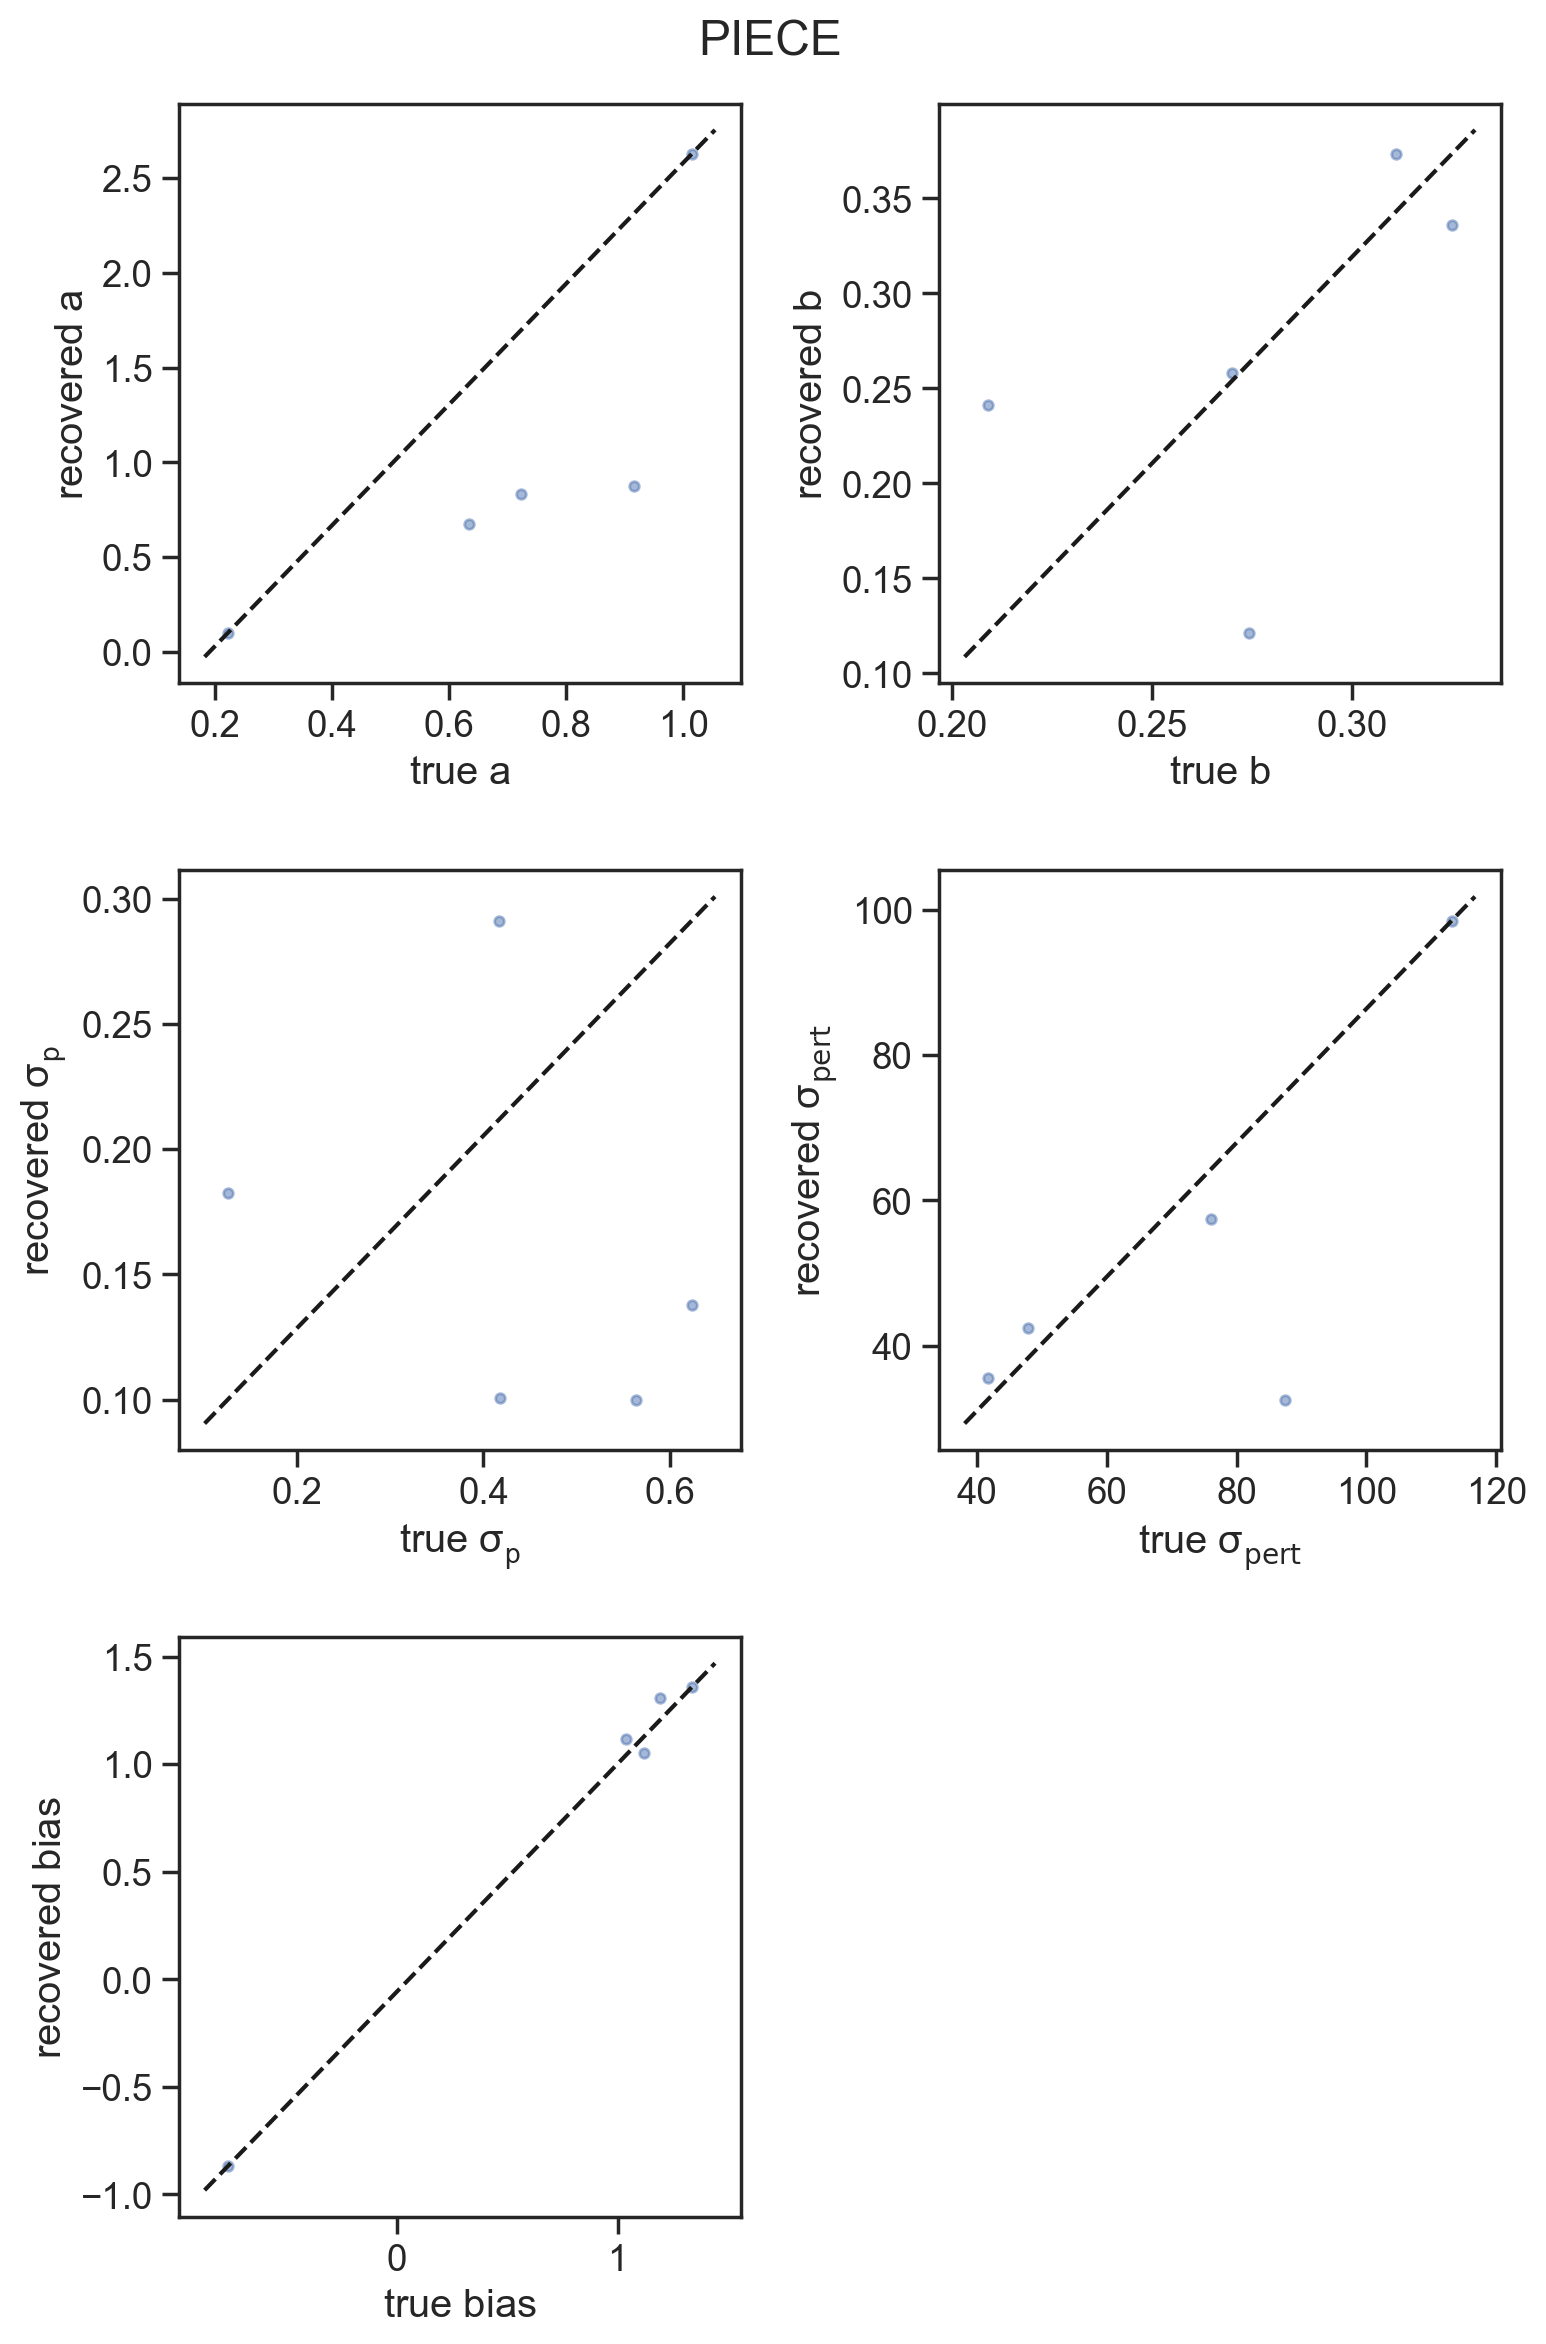

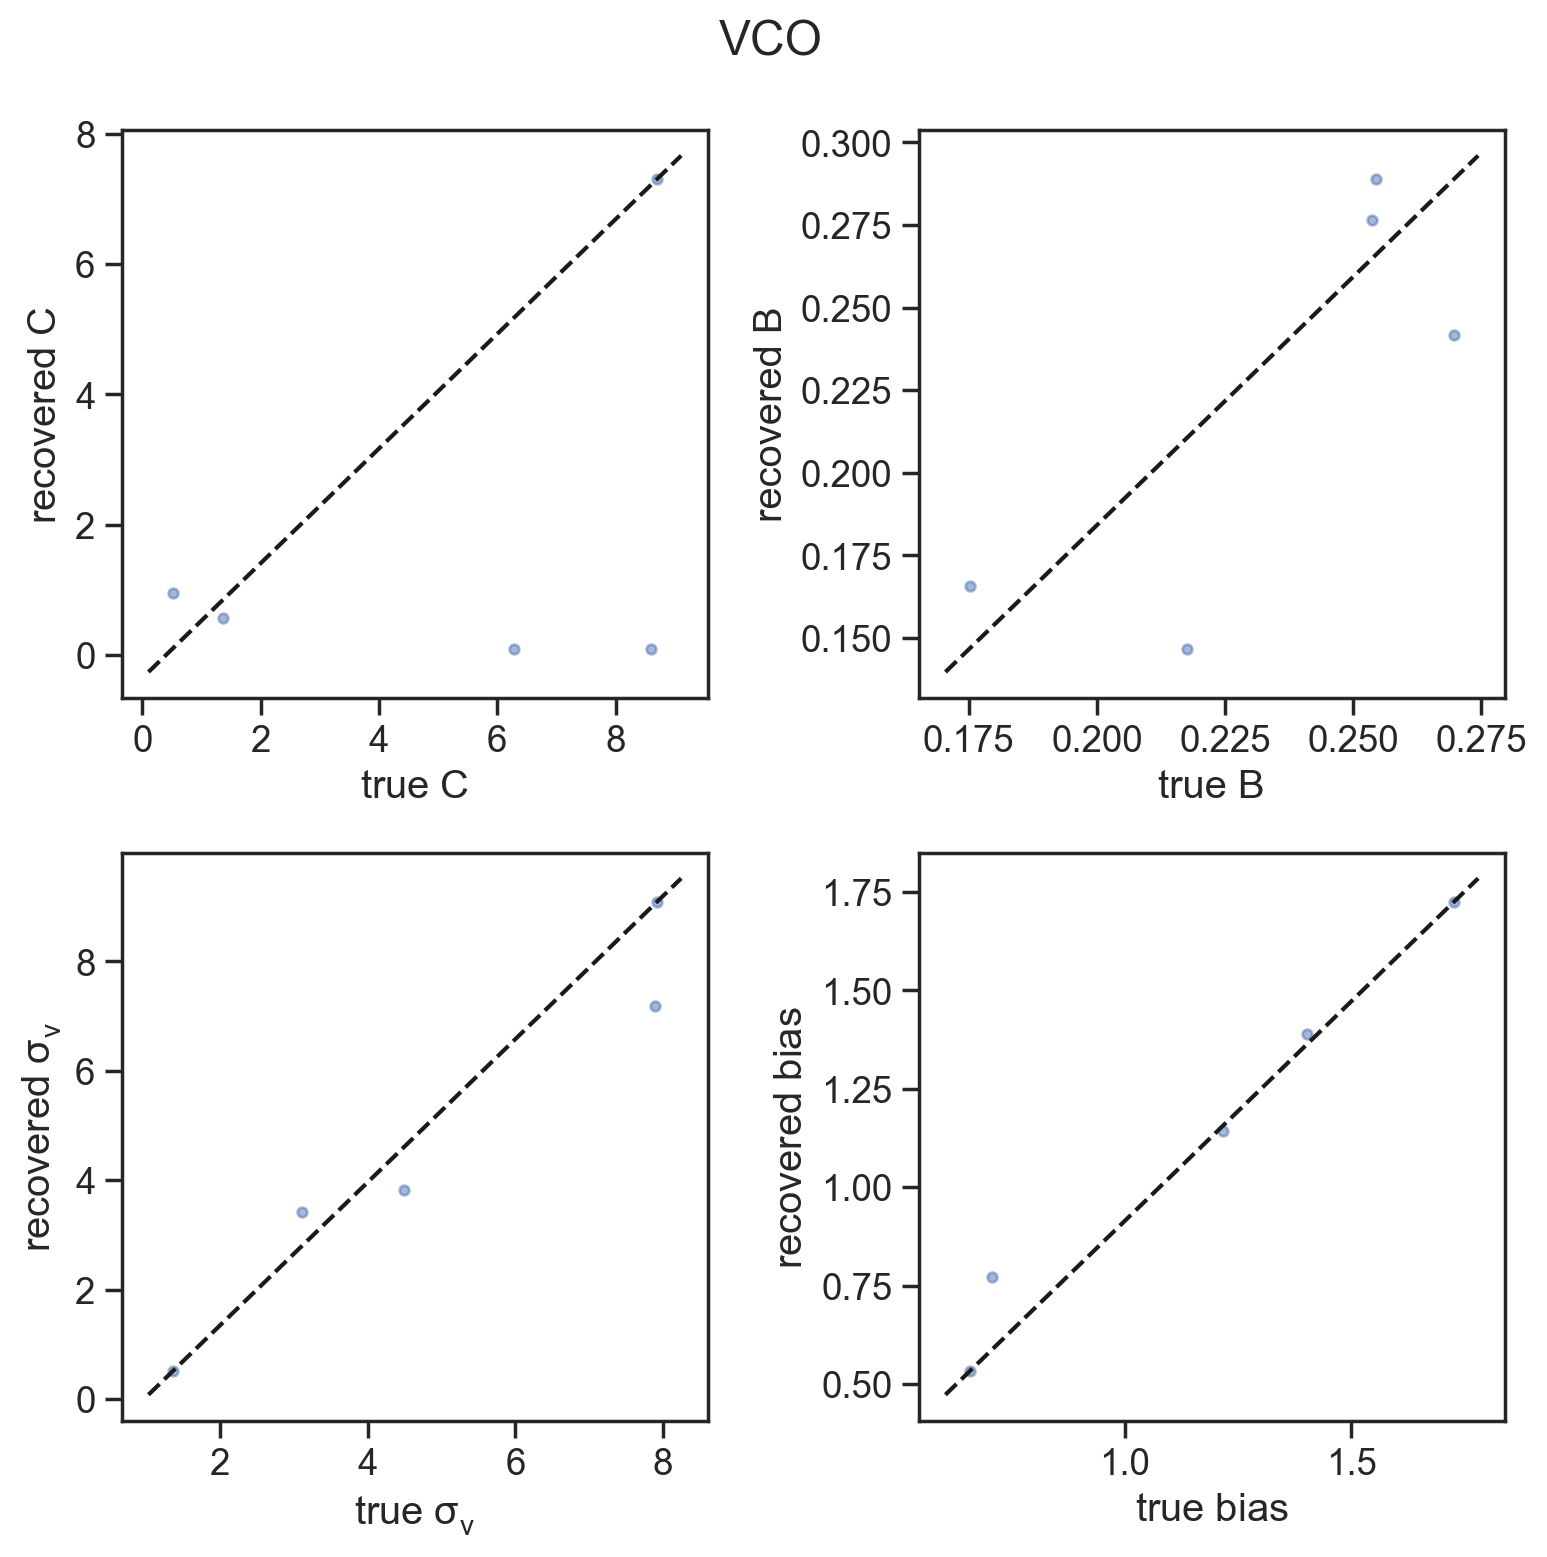

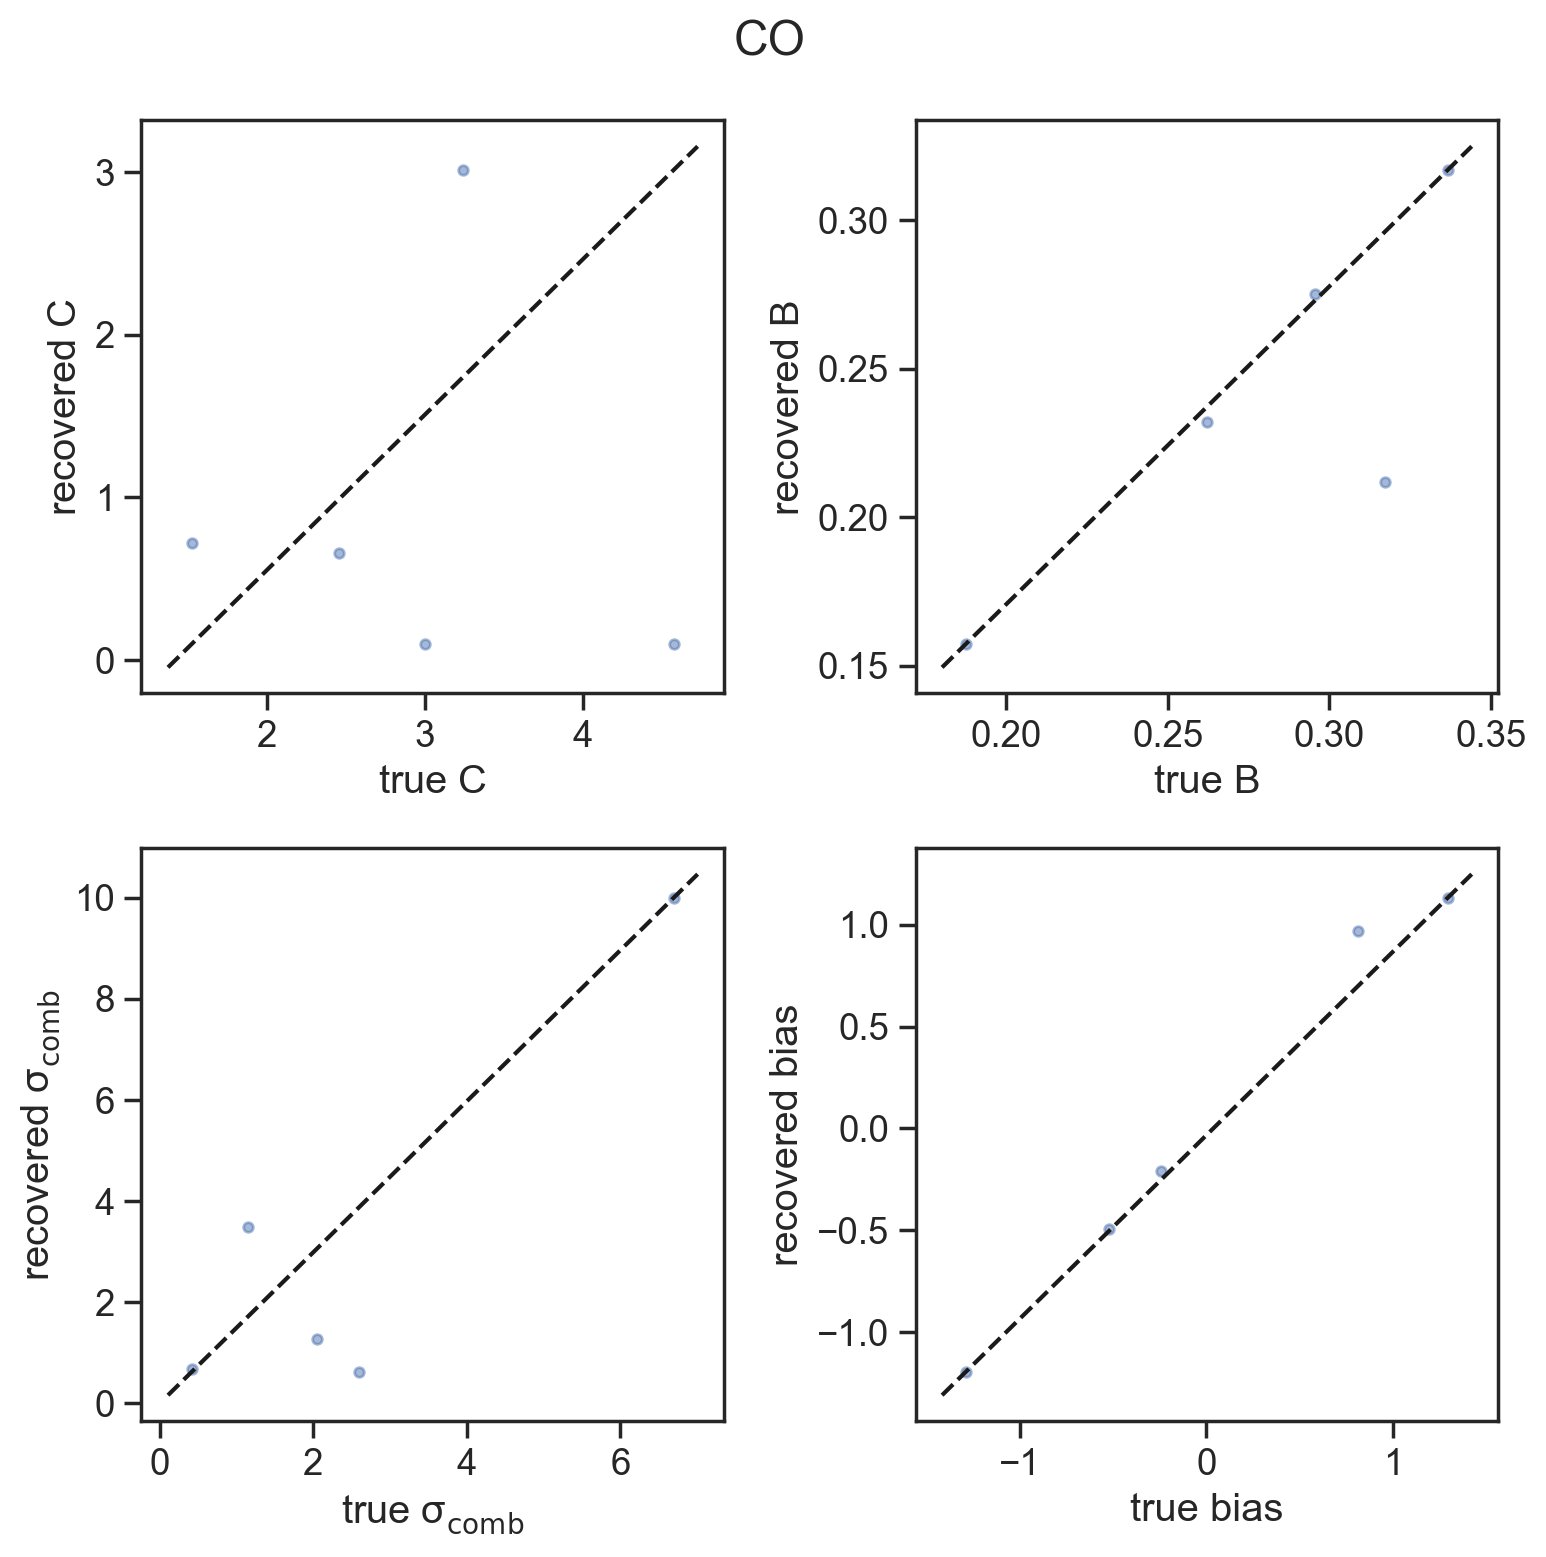

In [60]:
# Plot param recovery for PIECE
fig, axs = plt.subplots(3, 2, figsize=(8, 12))
xaxes = [r"true $a$", r"true $b$", r"true $\sigma_p$", r"true $\sigma_\text{pert}$", 
         r"true $bias$"] 
yaxes = [r"recovered $a$", r"recovered $b$", r"recovered $\sigma_p$", 
         r"recovered $\sigma_\text{pert}$", r"recovered $bias$"] 
for i, ax in enumerate(axs.flatten()[:-1]):
    ax.scatter(piece_simparams[:, i], piece_fitparams[:, i], alpha=0.5, s=12)
    ax.plot(ax.get_xlim(), ax.get_ylim(), color="k", linestyle="--")
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])
    plt.tight_layout()
    fig.suptitle("PIECE")
axs.flatten()[-1].set_axis_off()

# Plot param recovery for VCO
fig, axs = plt.subplots(2, 2, figsize=(8, 8))
xaxes = [r"true $C$", r"true B", r"true $\sigma_v$", r"true $bias$"] 
yaxes = [r"recovered $C$", r"recovered B", r"recovered $\sigma_v$", r"recovered $bias$"] 
for i, ax in enumerate(axs.flatten()):
    ax.scatter(vco_simparams[:, i], vco_fitparams[:, i], alpha=0.5, s=12)
    ax.plot(ax.get_xlim(), ax.get_ylim(), color="k", linestyle="--")
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])
    plt.tight_layout()
    fig.suptitle("VCO")

# Plot param recovery for CO
fig, axs = plt.subplots(2, 2, figsize=(8, 8))
xaxes = [r"true $C$", r"true B", r"true $\sigma_\text{comb}$", r"true bias"] 
yaxes = [r"recovered $C$", r"recovered B", r"recovered $\sigma_\text{comb}$", r"recovered bias"] 
for i, ax in enumerate(axs.flatten()):
    ax.scatter(co_simparams[:, i], co_fitparams[:, i], alpha=0.5, s=12)
    ax.plot(ax.get_xlim(), ax.get_ylim(), color="k", linestyle="--")
    ax.set(xlabel=xaxes[i], ylabel=yaxes[i])
    plt.tight_layout()
    fig.suptitle("CO")